# Personalized speech deepfake detection with PVP: technical report

Practical Work in AI, JKU Linz, 2026. This notebook is the technical report of the practical work.
It only **reads saved results**: no model and no audio are loaded. Every number is read from
saved score and analysis files or recomputed from them with the project scripts.

**Questions**

1. Can the published PVP results (Xue et al., 2026, Table 2, MMS-300M) be reproduced
   with the public code and the official protocols?
2. How does PVP behave when the speaker is enrolled in one language and tested in another
   (German/English, same speaker)?

**Main findings**

- **Reproduction:** EN-Famous EER 7.34% (paper 7.24%), ZH-Famous 12.24% (paper 11.37%).
  Every scientific run was replayed with bit-identical scores.
- **Cross-language (EMIME, Qwen3-TTS clones):** the EER rises from 19.8% to 39.5% with a German
  profile on English speech, and from 22.5% to 28.1% in the reverse direction.
- **The cause is mainly genuine speech:** a German profile rejects the same speaker's genuine
  English speech much more often. English clones are not accepted more often.
- **Generator dependence:** the loss is large for Qwen3-TTS, small for VoxCPM2, and not
  detectable for XTTS v2, whose clones PVP detects easily.
- **Phoneme profiles (exploratory):** the German and English profiles of the same talker share
  only about 4 of their 12 most reliable phonemes.

**Contents:** 1 Method · 2 Reproduction · 3 Cross-language evaluation · 4 Confirmation sets ·
5 Phoneme profiles · 6 Replays · 7 Conclusion and limitations

## 1. Method

PVP is a *personalized* detector. It protects one known speaker and is fitted only on genuine
recordings of that speaker; it never sees deepfakes during fitting.

1. **Enrollment.** A phoneme recognizer (CTC) finds each speech sound in the speaker's genuine
   recordings. MMS-300M features are averaged per phoneme occurrence.
2. **Profile.** One Gaussian mixture model (GMM) per phoneme with at least 5 occurrences, plus one
   GMM on ECAPA speaker embeddings. Each phoneme gets a *weight*: the mean log-likelihood of its
   own enrollment data, so a high weight means the speaker pronounces it consistently.
   The 12 phonemes with the highest weights form the *top-k* set.
3. **Test.** A recording is scored against the claimed speaker's profile. The phoneme score
   (top-k phonemes) and the speaker score are fused with weight 0.8 for the phoneme part.
   **Higher score = more like the genuine speaker.** With too few top-k phonemes, upstream
   falls back to all phonemes (Level 2) or broad sound classes (Level 3).

**Metrics.** EER (equal error rate, lower is better) with the upstream function, and ROC-AUC
(higher is better) with scikit-learn.

| Decision | Reason |
| --- | --- |
| Unchanged upstream code (`original/PVP/`, commit `1eed3f4`); our scripts only wrap and record | A reproduction must test the published method. |
| Upstream code settings where code and paper text differ | The code can be run exactly; the differences are listed in `docs/reproduction.md`. |
| Official protocols unchanged; every trial recorded, also failed ones | Removing trials after seeing results would be tuning on the test set. |
| Default MMS-300M backbone only | Scope decision of 2026-11-11. |
| Cross-language analysis plan committed before the first EMIME score | The main results cannot be chosen after the fact. |
| Scientific runs only from a clean commit, each replayed once | Every number can be traced and regenerated. |

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from analyze_emime import MAIN_RUNS, TALKERS, load_run  # same code as the runs and analyses
from compare_runs import compare
from evaluate_pvp import evaluate, metrics, read_scores

RUNS = ROOT / "results/runs"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a94"  # colorblind-safe
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.2f}".format


def load(path):
    return json.loads((ROOT / path).read_text())


A = {name: load(f"results/analysis/{folder}/analysis.json") for name, folder in {
    "qwen3tts": "emime/20261116T145229Z", "voxcpm2": "emime-voxcpm2/20261117T144059Z",
    "xtts": "emime-xtts/20261117T150247Z", "finnish": "emime-finnish/20261116T144957Z",
    "vcc2020": "vcc2020/20261117T083513Z", "quality": "quality-correlation/20261117T173911Z",
}.items()}


def nines(scores):
    """-log10(1 - score): spreads saturated scores, keeps their order (EER, AUC unchanged)."""
    return -np.log10(np.clip(1 - np.asarray(scores, dtype=float), 1e-16, None))


def ci(entry, sign="+"):
    low, high = entry["ci95"]
    return f"{entry['pooled']:{sign}.1f} [{low:{sign}.1f}, {high:{sign}.1f}]"

## 2. Reproduction (Phases 4 and 5)

Two benchmarks from the authors, each with 10 speakers and fixed enrollment and test lists:
**ZH-Famous** (Mandarin) and **EN-Famous** ("Famous Figures", English). Before the runs, every
file was decoded and compared by audio hash. Two problems were found and kept, as decided:
some bona fide test files are exact copies of enrollment files, and some spoofs are only
10-40 ms long. The table recomputes the metrics from `scores.csv` and checks them against the
saved `metrics.json`.

In [2]:
FAMOUS = {  # name: run, dataset check prefix, config
    "ZH-Famous": ("20261110T161146Z-a7e7dcab", "zh-famous", "configs/pvp-zh-famous-mms.json"),
    "EN-Famous": ("20261110T194052Z-89c7e58d", "famous-figures", "configs/pvp-famous-figures-mms.json"),
}
famous, rows = {}, []
for name, (run_id, checks, config) in FAMOUS.items():
    trials = read_scores(RUNS / run_id / "scores.csv")
    result = evaluate(trials)
    assert result["pooled"] == load(f"results/runs/{run_id}/metrics.json")["pooled"]
    paper = load(config)["paper"]
    copies = load(f"results/datasets/{checks}-leakage.json")["identical_audio"]
    famous[name] = {"trials": trials, "result": result}
    rows.append({
        "benchmark": name,
        "bona fide": sum(t["label"] == "bonafide" for t in trials),
        "spoof": sum(t["label"] == "spoof" for t in trials),
        "spoof systems": len({t["source"] for t in trials if t["label"] == "spoof"}),
        "enrollment copies": copies["test_trials_equal_to_enroll_same_speaker"]["bonafide"],
        "failed": sum(t["status"] != "scored" for t in trials),
        "paper EER": paper["eer_percent"], "our EER": 100 * result["pooled"]["eer"],
        "paper AUC": paper["auc_percent"], "our AUC": 100 * result["pooled"]["auc"],
    })
pd.DataFrame(rows).set_index("benchmark")

,bona fide,spoof,spoof systems,enrollment copies,failed,paper EER,our EER,paper AUC,our AUC
benchmark,,,,,,,,,
ZH-Famous,32991,170930,5,60,10,11.37,12.24,94.58,93.62
EN-Famous,49151,297870,11,34,333,7.24,7.34,96.61,96.58


**Reading.** EN-Famous matches the paper within 0.1 EER points; ZH-Famous is 0.87 points worse.
The cause of that gap is not established. Candidates are the paper/code setting differences,
9 files missing from the ZH release, and an unknown code state behind the published table.
Nothing was tuned toward the paper values. All failed trials are spoofs: the 9 missing files and
very short files where ECAPA raises an error. Like upstream, they are left out of the metrics.

In [3]:
def eer_auc(trials):
    result = metrics([t["label"] == "bonafide" for t in trials], [float(t["score"]) for t in trials])
    return f"{100 * result['eer']:.2f} / {100 * result['auc']:.2f}"


def enrollment_copies(checks):
    groups = pd.read_csv(ROOT / f"results/datasets/{checks}-identical-audio.csv", dtype=str)
    enrolled = groups[groups.split == "enroll"][["group", "speaker"]].drop_duplicates()
    test = groups[(groups.split == "test") & (groups.label == "bonafide")]
    return set(test.merge(enrolled, on=["group", "speaker"])[["speaker", "file"]].itertuples(index=False))


checks = {}
for name, (_, prefix, _) in FAMOUS.items():
    trials = famous[name]["trials"]
    scored = [t for t in trials if t["status"] == "scored"]
    copies = enrollment_copies(prefix)
    checks[name] = {
        "main result": eer_auc(scored),
        "failed spoofs counted as accepted": eer_auc(
            scored + [{**t, "score": "1.0"} for t in trials if t["status"] != "scored"]),
        "without enrollment copies": eer_auc([t for t in scored if (t["speaker"], t["file"]) not in copies]),
    }
print("EER / AUC in percent")
pd.DataFrame(checks)

EER / AUC in percent


,ZH-Famous,EN-Famous
main result,12.24 / 93.62,7.34 / 96.58
failed spoofs counted as accepted,12.24 / 93.61,7.42 / 96.47
without enrollment copies,12.26 / 93.61,7.34 / 96.58


Both data problems change the EER by less than 0.1 points, so they do not explain the gap to the paper.

PVP scores are **saturated**: most lie between 0.9999 and 1. The left plots therefore show
$-\log_{10}(1-\text{score})$; a value of 5 means 0.99999. The transform keeps the order of
scores, so EER and AUC are unchanged. The dashed line is the EER threshold.

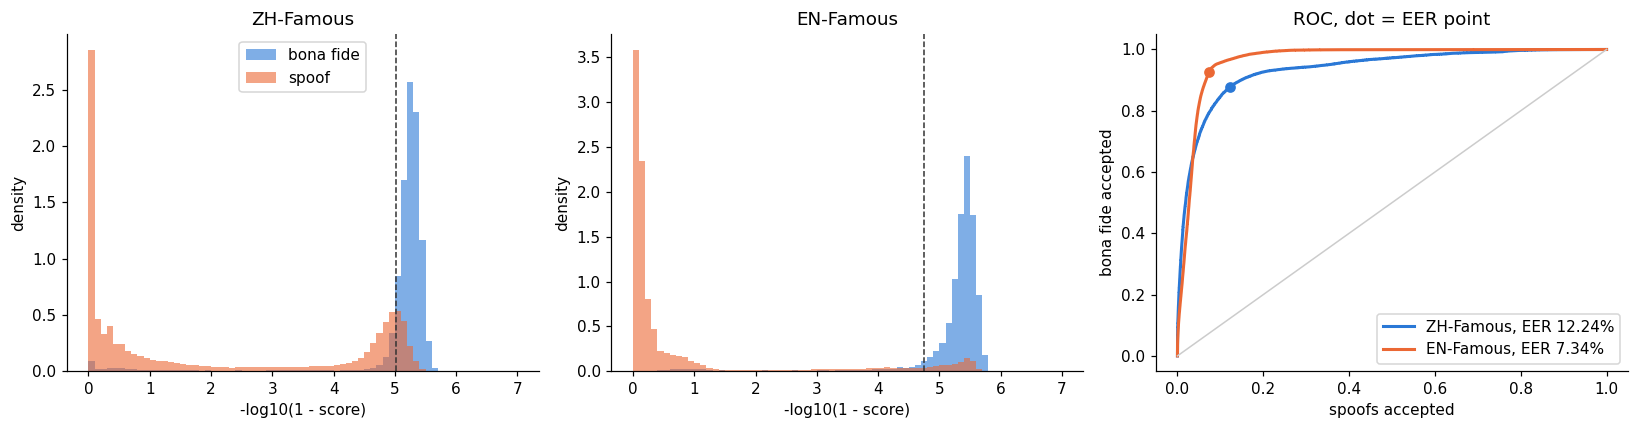

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.linspace(0, 7, 71)
for ax, (name, run), color in zip(axes, famous.items(), [BLUE, ORANGE]):
    scored = [t for t in run["trials"] if t["status"] == "scored"]
    labels = np.array([t["label"] == "bonafide" for t in scored])
    scores = np.array([float(t["score"]) for t in scored])
    for mask, label, c in [(labels, "bona fide", BLUE), (~labels, "spoof", ORANGE)]:
        ax.hist(np.clip(nines(scores[mask]), 0, 7), bins=bins, density=True, alpha=0.6, color=c, label=label)
    ax.axvline(nines(run["result"]["pooled"]["eer_threshold"]), color="#333", ls="--", lw=1)
    ax.set(title=name, xlabel="-log10(1 - score)", ylabel="density")
    fpr, tpr, _ = roc_curve(labels, scores)
    eer = run["result"]["pooled"]["eer"]
    axes[2].plot(fpr, tpr, color=color, lw=2, label=f"{name}, EER {100 * eer:.2f}%")
    axes[2].plot(eer, 1 - eer, "o", color=color)
axes[0].legend()
axes[2].plot([0, 1], [0, 1], color="#ccc", lw=1)
axes[2].set(title="ROC, dot = EER point", xlabel="spoofs accepted", ylabel="bona fide accepted")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

The pooled EER hides large differences between speakers and spoof systems. For one system,
all bona fide trials are compared with only that system's spoofs.

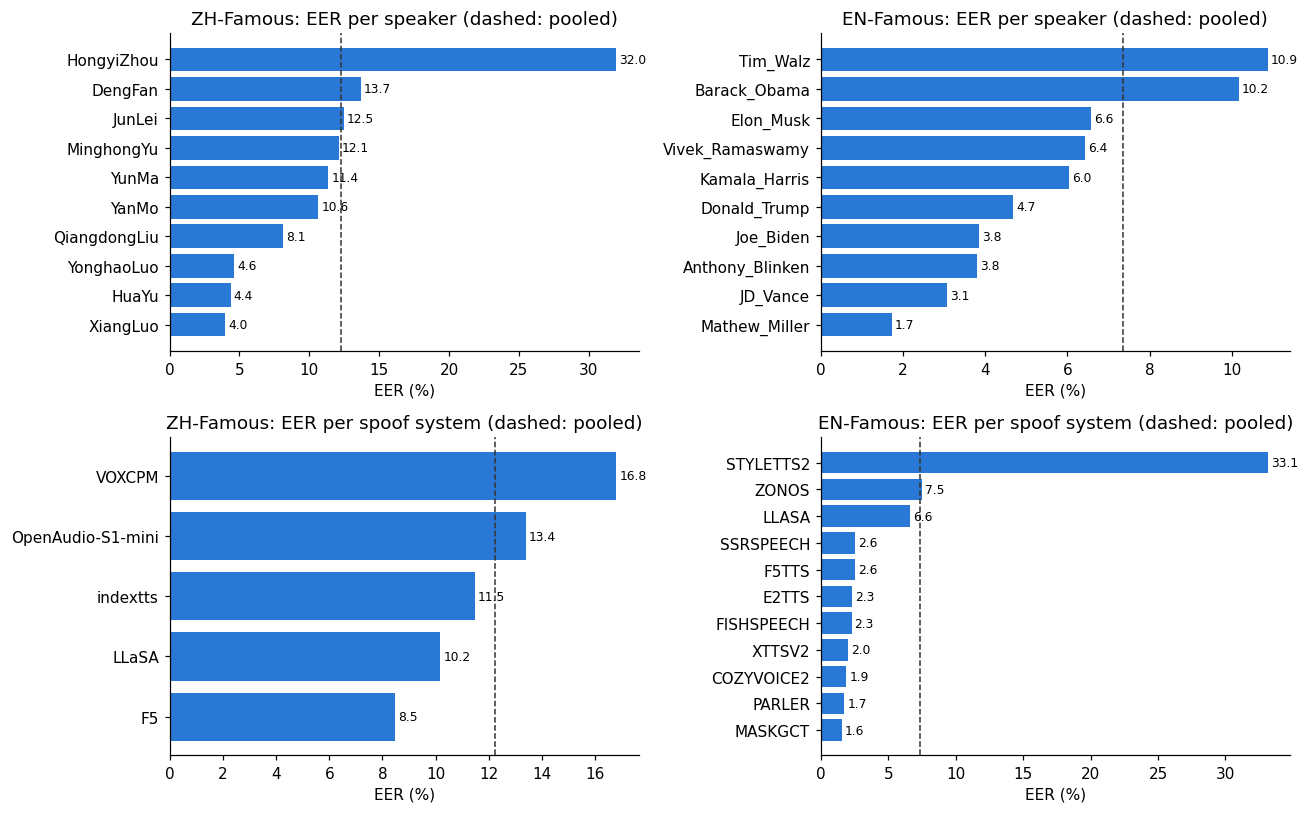

In [5]:
def per_system(trials):
    scored = [t for t in trials if t["status"] == "scored"]
    bona = [float(t["score"]) for t in scored if t["label"] == "bonafide"]
    result = {}
    for system in sorted({t["source"] for t in scored if t["label"] == "spoof"}):
        spoof = [float(t["score"]) for t in scored if t["source"] == system and t["label"] == "spoof"]
        result[system] = 100 * metrics([1] * len(bona) + [0] * len(spoof), bona + spoof)["eer"]
    return pd.Series(result).sort_values()


fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for col, (name, run) in enumerate(famous.items()):
    speakers = pd.Series({s: 100 * m["eer"] for s, m in run["result"]["per_speaker"].items()}).sort_values()
    for ax, series, what in [(axes[0, col], speakers, "speaker"), (axes[1, col], per_system(run["trials"]), "spoof system")]:
        ax.barh(series.index, series.values, color=BLUE)
        ax.axvline(100 * run["result"]["pooled"]["eer"], color="#333", ls="--", lw=1)
        ax.bar_label(ax.containers[0], fmt="%.1f", fontsize=8, padding=2)
        ax.set(title=f"{name}: EER per {what} (dashed: pooled)", xlabel="EER (%)")
plt.tight_layout()
plt.show()

**Reading.** On ZH-Famous, HongyiZhou is an outlier (EER about 32%) and VOXCPM is the hardest
system. On EN-Famous, most systems are easy, but STYLETTS2 reaches an EER of about 33%.
Barack_Obama has 48% of all EN-Famous test trials and strongly shapes the pooled result.

## 3. Cross-language evaluation (EMIME, Phase 6)

> New evaluation with our own protocol, not a reproduction. No paper value exists.

**Data.** The EMIME bilingual database: 14 German talkers (GF1-GF7, GM1-GM7) read 145 German and
145 English sentences. The sentences are split the same way in both languages: 60 for enrollment,
10 as voice prompts for cloning, 75 for testing. No translation crosses enrollment and test.

**Clones.** Qwen3-TTS 1.7B (zero-shot voice cloning) speaks each test sentence in the talker's
voice, from a German or an English voice prompt: 4,200 clones. All clones stay in the analysis,
because a real attacker does not filter their fakes either.

**Design.** Each talker gets two profiles, German (DE) and English (EN). Every test trial is
scored with both. A *cell* is (profile language, test language). The analysis plan
(`protocols/emime/analysis-plan.md`) was committed before the first score. The unit of inference
is the talker (n = 14): 95% intervals come from a talker bootstrap, p-values from exact sign-flip
tests with Holm correction. The planned primary contrasts:

| | Definition |
| --- | --- |
| P1 | English test: EER with the DE profile minus EER with the EN profile |
| P2 | German test: EER with the EN profile minus EER with the DE profile |
| P3 | DE profile, fixed threshold: genuine English rejected minus genuine German rejected |
| P4 | DE profile, fixed threshold: English clones accepted minus German clones accepted |

P1 and P2 count as a *meaningful loss* when the whole interval lies above +2 EER points.
P3 and P4 separate the effect on genuine speech from the effect on clones.

In [6]:
def s1(analysis):
    return analysis["S1"] if "S1" in analysis else analysis["secondary"]["S1"]


cells = s1(A["qwen3tts"])
grid = pd.DataFrame({
    f"{t.upper()} test": {f"{e.upper()} profile": f"{c['eer']['pooled']:.1f} [{c['eer']['ci95'][0]:.1f}, "
                          f"{c['eer']['ci95'][1]:.1f}] / {c['auc']['pooled']:.1f}"
                          for e in ["de", "en"] for c in [cells[f"enroll_{e}_test_{t}"]]}
    for t in ["de", "en"]})
print("EER [95% CI] / AUC, percent")
display(grid)

primary = A["qwen3tts"]["primary"]
pd.DataFrame({p: {"value [95% CI]": ci(primary[p]), "talkers positive": f"{primary[p]['talkers_positive']} of 14",
                  "p (Holm)": f"{primary[p]['p_holm']:.4f}", "reading": primary[p].get("reading", "")}
              for p in ["P1", "P2", "P3", "P4"]}).T

EER [95% CI] / AUC, percent


,DE test,EN test
DE profile,"19.8 [17.7, 22.0] / 87.3","39.5 [35.8, 43.4] / 63.1"
EN profile,"28.1 [24.0, 32.5] / 78.0","22.5 [20.5, 24.5] / 84.2"


,value [95% CI],talkers positive,p (Holm),reading
P1,"+17.0 [+13.9, +20.1]",14 of 14,0.0005,meaningful loss
P2,"+8.3 [+5.0, +11.9]",13 of 14,0.0005,meaningful loss
P3,"+73.9 [+67.9, +78.1]",14 of 14,0.0005,
P4,"-12.4 [-14.6, -10.1]",0 of 14,0.0005,


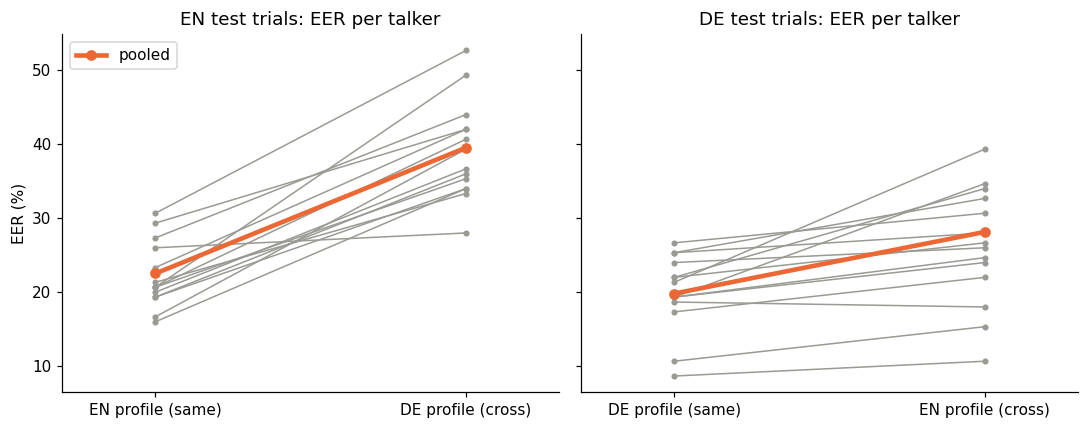

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, test, other in [(axes[0], "en", "de"), (axes[1], "de", "en")]:
    same = cells[f"enroll_{test}_test_{test}"]["eer"]
    cross = cells[f"enroll_{other}_test_{test}"]["eer"]
    for t in TALKERS:
        ax.plot([0, 1], [same["per_talker"][t], cross["per_talker"][t]], color=GREY, marker="o", ms=3, lw=1)
    ax.plot([0, 1], [same["pooled"], cross["pooled"]], color=ORANGE, marker="o", lw=3, label="pooled")
    ax.set_xticks([0, 1], [f"{test.upper()} profile (same)", f"{other.upper()} profile (cross)"])
    ax.set(title=f"{test.upper()} test trials: EER per talker", xlim=(-0.3, 1.3))
axes[0].set_ylabel("EER (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Reading.** Cross-language enrollment loses detection performance in both directions:
P1 +17.0 points (14 of 14 talkers) and P2 +8.3 points (13 of 14), both meaningful by the plan rule.
The German profile is hurt more on English test speech than the reverse.

**Why?** P3 and P4 answer this. With the German profile and its own threshold, genuine English speech
is rejected 73.9 points more often than genuine German speech, while English clones are accepted
12.4 points *less* often than German clones. The loss therefore comes from genuine speech: the
profile treats the speaker's own English as "not this speaker". The plot below shows this shift.

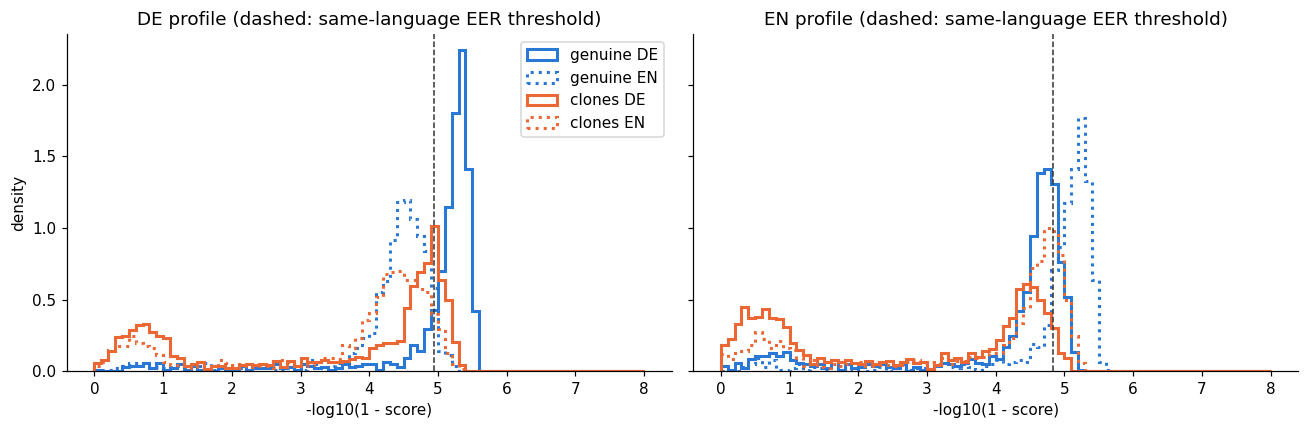

In [8]:
groups = {"genuine DE": (True, "de"), "genuine EN": (True, "en"), "clones DE": (False, "de"), "clones EN": (False, "en")}
styles = {"genuine DE": (BLUE, "-"), "genuine EN": (BLUE, ":"), "clones DE": (ORANGE, "-"), "clones EN": (ORANGE, ":")}
thresholds = {"de": primary["P3"]["threshold"], "en": A["qwen3tts"]["secondary"]["S2"]["threshold"]}
emime = {lang: load_run(run_id, set())[0] for lang, run_id in MAIN_RUNS.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.linspace(0, 8, 81)
for ax, (lang, run) in zip(axes, emime.items()):
    for group, (genuine, test) in groups.items():
        values = np.concatenate([nines(run[t]["score"][(run[t]["label"] == genuine) & (run[t]["lang"] == test)])
                                 for t in TALKERS])
        color, ls = styles[group]
        ax.hist(np.clip(values, 0, 8), bins=bins, density=True, histtype="step", lw=2, color=color, ls=ls, label=group)
    ax.axvline(nines(thresholds[lang]), color="#333", ls="--", lw=1)
    ax.set(title=f"{lang.upper()} profile (dashed: same-language EER threshold)", xlabel="-log10(1 - score)")
axes[0].set_ylabel("density")
axes[0].legend()
plt.tight_layout()
plt.show()

Two more checks per cell. **Wrong-speaker control:** each trial is scored against the profile of
another talker of the same sex. If PVP detects the speaker and not only the language, the EER must
rise. **Branches:** the fused score is split into its phoneme part and its speaker (ECAPA) part.

In [9]:
secondary, control = A["qwen3tts"]["secondary"], A["qwen3tts"]["control"]
pd.DataFrame({
    f"{e.upper()} profile, {t.upper()} test": {
        "EER right profile": control[cell]["right_eer"],
        "EER wrong speaker": control[cell]["wrong_eer"],
        "AUC phoneme part": secondary["S5"][f"{cell}_phoneme"]["auc"],
        "AUC speaker part": secondary["S5"][f"{cell}_speaker"]["auc"],
    } for e in ["de", "en"] for t in ["de", "en"] for cell in [f"enroll_{e}_test_{t}"]}).T

,EER right profile,EER wrong speaker,AUC phoneme part,AUC speaker part
"DE profile, DE test",19.81,47.14,79.47,89.69
"DE profile, EN test",39.52,56.14,69.00,48.56
"EN profile, DE test",28.14,42.71,75.06,73.87
"EN profile, EN test",22.52,51.29,72.78,88.91


**Reading.**

- The wrong-speaker EER is about 15-29 points higher in every cell, so PVP detects the speaker,
  also across languages.
- In the same language, the speaker part is stronger than the phoneme part. With the German
  profile on English trials, the speaker part falls to chance (AUC 48.6), while the phoneme part
  keeps AUC 69.0. Against English clones made from a *German* voice prompt, the speaker part
  drops to AUC 28.9: these clones sound more like the German enrollment than the talker's
  real English does.
- Even on genuine speech alone, the German profile separates the talker's German from their
  English with AUC 87.6 (S3). The language itself is a strong signal in the profile.
- Leaving out the 63 clones flagged in quality checks changes P1-P4 by less than 0.3 points (S7).

## 4. Confirmation sets

The analysis plan fixed three confirmation sets before their scores existed:
other clone generators, other talkers and language (Finnish), and an independent attack
corpus (VCC2020).

### 4.1 Other generators

The same protocol with clones from VoxCPM2 and XTTS v2 (4,200 each). Genuine trials and
profiles are identical to the main runs; only the clones change.

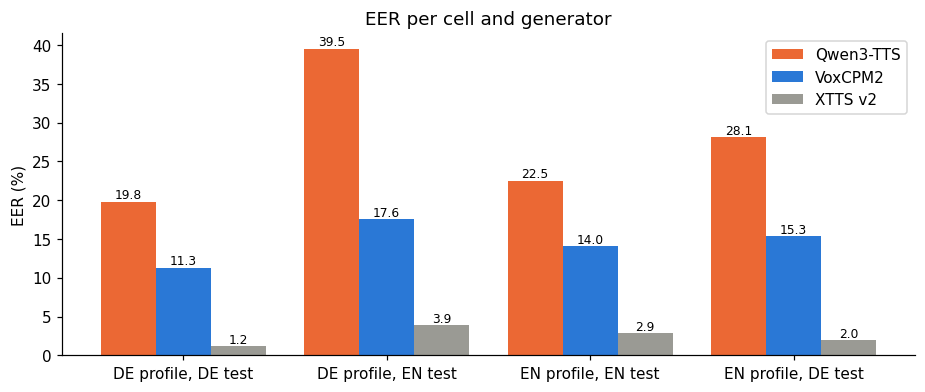

,Qwen3-TTS,VoxCPM2,XTTS v2
P1,"+17.0 [+13.9, +20.1]","+3.5 [+1.9, +5.0]","+1.0 [-0.9, +2.6]"
P2,"+8.3 [+5.0, +11.9]","+4.0 [+0.8, +7.3]","+0.8 [-0.2, +1.9]"
P3,+73.9,+42.7,+0.8
P4,-12.4,-5.9,+7.0
P1 reading,meaningful loss,"loss, size uncertain",inconclusive
P2 reading,meaningful loss,"loss, size uncertain",no meaningful change; PVP transfers in this se...
cause,the genuine shift dominates,the genuine shift dominates,the clone shift dominates


In [10]:
GENERATORS = {"Qwen3-TTS": "qwen3tts", "VoxCPM2": "voxcpm2", "XTTS v2": "xtts"}
CELLS = [("de", "de"), ("de", "en"), ("en", "en"), ("en", "de")]

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(CELLS))
for i, (label, key) in enumerate(GENERATORS.items()):
    values = [s1(A[key])[f"enroll_{e}_test_{t}"]["eer"]["pooled"] for e, t in CELLS]
    bars = ax.bar(x + (i - 1) * 0.27, values, 0.27, color=[ORANGE, BLUE, GREY][i], label=label)
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
ax.set_xticks(x, [f"{e.upper()} profile, {t.upper()} test" for e, t in CELLS])
ax.set(ylabel="EER (%)", title="EER per cell and generator")
ax.legend()
plt.show()

pd.DataFrame({label: {**{p: ci(A[key]["primary"][p]) for p in ["P1", "P2"]},
                      **{p: f"{A[key]['primary'][p]['pooled']:+.1f}" for p in ["P3", "P4"]},
                      "P1 reading": A[key]["primary"]["P1"]["reading"],
                      "P2 reading": A[key]["primary"]["P2"]["reading"],
                      "cause": A[key]["primary"]["RQ2_reading"]}
              for label, key in GENERATORS.items()})

**Reading.** P1 and P2 are positive for all three generators, but their size depends on how hard
the clones are. With XTTS v2, same-language EER is only 1.2-2.9% and no meaningful cross-language
loss remains. P3 depends on the threshold, which moves with the clones (it is low for XTTS v2), so
it is not a generator-independent measure of the genuine shift; the S3 result above is.

### 4.2 Finnish talkers

The EMIME Finnish talkers (Finnish/English) test the genuine-speech effect (S3) on a second
language pair: can a profile separate the talker's two languages on genuine speech only?

In [11]:
finnish = A["finnish"]["finnish"]
s3 = A["qwen3tts"]["secondary"]["S3"]
print("AUC [95% CI], genuine speech only: native language vs. English")
pd.DataFrame({
    "German talkers": {"native-language profile": ci(s3["enroll_de_genuine"], ""),
                       "English profile": ci(s3["enroll_en_genuine"], "")},
    "Finnish talkers": {"native-language profile": ci(finnish["S3_enroll_fi_genuine"], ""),
                        "English profile": ci(finnish["S3_enroll_en_genuine"], "")},
}).T

AUC [95% CI], genuine speech only: native language vs. English


,native-language profile,English profile
German talkers,"87.6 [85.4, 89.7]","82.7 [80.0, 85.2]"
Finnish talkers,"85.2 [82.0, 88.1]","83.7 [81.1, 86.5]"


**Reading.** Confirmed: for Finnish talkers too, both profiles separate the talker's own two
languages well (AUC about 84-85, all 14 talkers above 50).

### 4.3 VCC2020 voice conversion

VCC2020 Task 2 contains 28 teams' English conversions into two EMIME talkers (GF1, GM7).
This is an independent attack corpus, not generated by us.

In [12]:
vcc = A["vcc2020"]["vcc2020"]
pd.DataFrame({name: {"EER, DE profile": v["german_profile"]["eer"], "EER, EN profile": v["english_profile"]["eer"],
                     "difference": v["eer_difference"]}
              for name, v in {**vcc["per_talker"], "pooled": vcc["pooled"]}.items()}).T

,"EER, DE profile","EER, EN profile",difference
GF1,1.07,0.18,0.89
GM7,4.04,3.64,0.39
pooled,2.70,4.46,-1.77


**Reading.** Per talker, the German profile is worse on English speech, as expected, but both
differences are below one EER step (75 genuine trials per talker give steps of about 1.3 points),
and the pooled sign reverses. PVP detects these conversions very easily (AUC above 99%), so there
is little room for a language effect. Weak evidence only.

### 4.4 Clone quality and PVP score (exploratory)

> Not in the analysis plan; defined and committed after the generator results.

Does a more natural or more speaker-like clone get a higher PVP score inside one generator?
Spearman correlation per talker and cell, averaged over the 14 talkers. Quality measures:
UTMOS (predicted naturalness), WavLM speaker similarity to the profile, character error rate
(Whisper), and length error against the genuine recording.

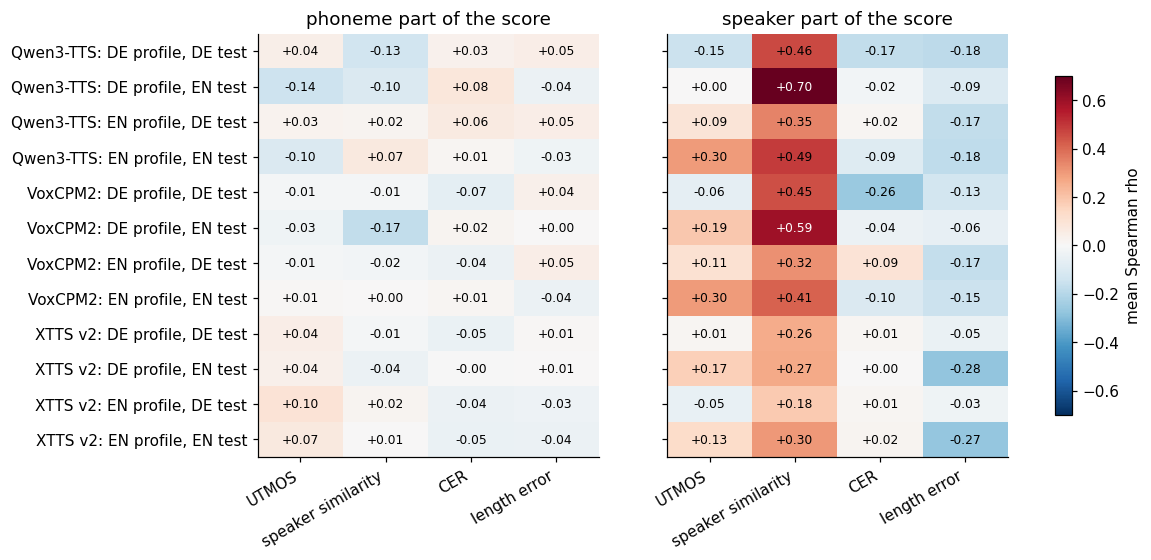

In [13]:
MEASURES = {"utmos": "UTMOS", "sim_profile": "speaker similarity", "cer": "CER", "length_error": "length error"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, part in zip(axes, ["phoneme", "speaker"]):
    table = pd.DataFrame({
        f"{label}: {cell[8:10].upper()} profile, {cell[-2:].upper()} test":
            {name: values[measure][part]["mean_rho"] for measure, name in MEASURES.items()}
        for label, key in GENERATORS.items()
        for cell, values in A["quality"]["generators"][key]["clones"].items()}).T
    image = ax.imshow(table.values, cmap="RdBu_r", vmin=-0.7, vmax=0.7, aspect="auto")
    for (i, j), v in np.ndenumerate(table.values):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.5 else "black")
    ax.set_xticks(range(len(MEASURES)), table.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(table)), table.index)
    ax.set_title(f"{part} part of the score")
fig.colorbar(image, ax=axes, label="mean Spearman rho", shrink=0.8)
plt.show()

**Reading.** The phoneme part, which carries 80% of the score, barely follows any quality measure
(|rho| at most 0.17). The speaker part follows WavLM speaker similarity, as expected for two
speaker embeddings. So inside one generator, more natural or more intelligible clones are not
harder to detect. The generator ranking (Qwen3-TTS hardest, XTTS v2 easiest) matches the UTMOS
ranking, but these measures do not explain it; generator-specific acoustic properties are more likely.

## 5. Phoneme profiles: German vs. English (exploratory)

> Exploratory and descriptive. It uses only the enrollment profiles, no test score. It is not
> the planned phoneme-level analysis (RQ3), which needs per-occurrence scores that the runner
> does not store yet.

Which phonemes does PVP rely on in each language? A phoneme gets a model only with at least
5 occurrences in enrollment. Following the plan's rule, a phoneme is **shared** for a talker if
both the German and the English profile have a model for it, and **language-specific** otherwise.

In [14]:
profiles = {lang: {t: joblib.load(RUNS / run_id / "profiles" / f"{t}.joblib") for t in TALKERS}
            for lang, run_id in MAIN_RUNS.items()}
rows, top_counts = {}, {"de": Counter(), "en": Counter()}
for t in TALKERS:
    weights = {lang: profiles[lang][t]["phoneme_weights"] for lang in profiles}
    top = {lang: set(profiles[lang][t]["top_k_set"]) for lang in profiles}
    shared = set(weights["de"]) & set(weights["en"])
    for lang in profiles:
        top_counts[lang].update(top[lang])
    rows[t] = {
        "models DE": len(weights["de"]), "models EN": len(weights["en"]), "shared": len(shared),
        "DE top-12 shared": len(top["de"] & shared), "EN top-12 shared": len(top["en"] & shared),
        "in both top-12": len(top["de"] & top["en"]),
        "weight rank rho": spearmanr([weights["de"][p] for p in shared], [weights["en"][p] for p in shared])[0],
    }
table = pd.DataFrame(rows).T
table.loc["mean"] = table.mean()
table.style.format(lambda v: f"{v:.2f}".rstrip("0").rstrip("."))

,models DE,models EN,shared,DE top-12 shared,EN top-12 shared,in both top-12,weight rank rho
GF1,38,43,29,10,8,4,0.22
GF2,38,43,30,9,6,3,0.59
GF3,37,43,29,9,8,4,0.47
GF4,38,43,30,9,7,4,0.73
GF5,37,44,30,9,7,4,0.5
GF6,37,41,28,7,8,5,0.71
GF7,38,44,30,9,7,5,0.49
GM1,37,43,29,7,6,4,0.59
GM2,38,42,29,8,8,5,0.56
GM3,37,42,29,7,7,4,0.25


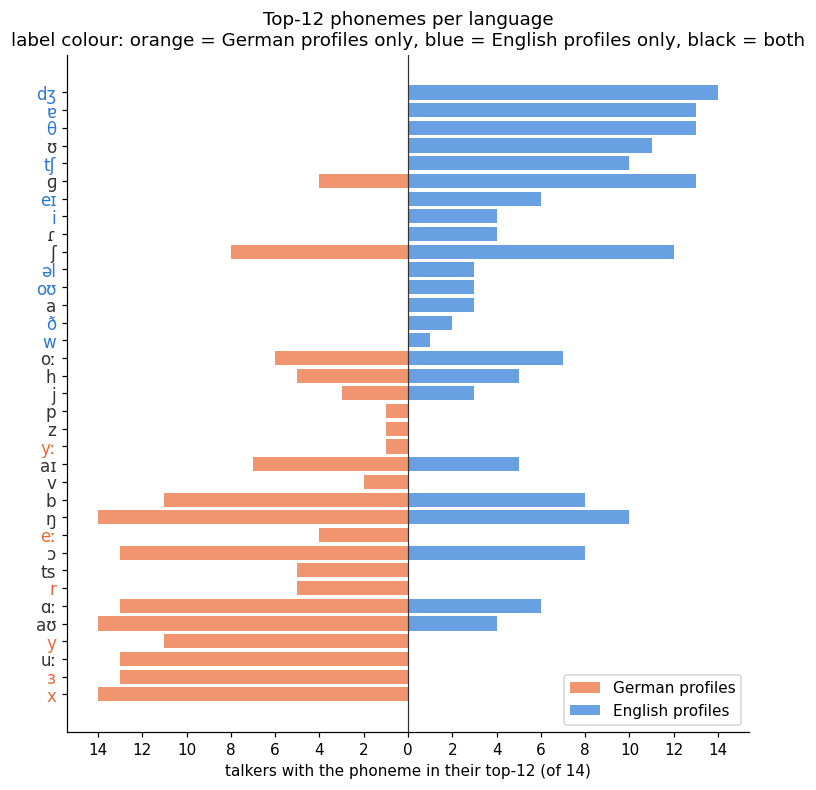

In [15]:
only = {lang: set().union(*(profiles[lang][t]["phoneme_weights"] for t in TALKERS))
        - set().union(*(profiles[other][t]["phoneme_weights"] for t in TALKERS))
        for lang, other in [("de", "en"), ("en", "de")]}
phonemes = sorted(set(top_counts["de"]) | set(top_counts["en"]),
                  key=lambda p: top_counts["en"][p] - top_counts["de"][p])
colors = [ORANGE if p in only["de"] else BLUE if p in only["en"] else "#333" for p in phonemes]

fig, ax = plt.subplots(figsize=(8, 8))
y = np.arange(len(phonemes))
ax.barh(y, [-top_counts["de"][p] for p in phonemes], color=ORANGE, alpha=0.7, label="German profiles")
ax.barh(y, [top_counts["en"][p] for p in phonemes], color=BLUE, alpha=0.7, label="English profiles")
ax.set_yticks(y, phonemes, fontsize=11)
for label, color in zip(ax.get_yticklabels(), colors):
    label.set_color(color)
ax.axvline(0, color="#333", lw=0.8)
ax.set_xticks(range(-14, 15, 2), [abs(v) for v in range(-14, 15, 2)])
ax.set(xlabel="talkers with the phoneme in their top-12 (of 14)",
       title="Top-12 phonemes per language\nlabel colour: orange = German profiles only, "
             "blue = English profiles only, black = both")
ax.legend(loc="lower right")
plt.show()

**Reading (exploratory).**

- Each profile has models for about 37-44 phonemes, and about 29 of them are shared between the
  two languages of a talker.
- The top-12 sets differ strongly. On average only about 4 phonemes are in both top-12 sets.
  About 8 of the 12 German top phonemes also have a model in the English profile, so the
  German profile can still find most of its top phonemes in English speech; this matches the rare
  fallback to Level 2 in cross-language trials.
- German profiles favour sounds such as /x/, /ŋ/, /aʊ/ and German vowels; English profiles favour
  /dʒ/, /θ/, /ɡ/ and /ɐ/. Some English top phonemes (/θ/, /dʒ/, /ɐ/) never get a model in a
  German profile. /θ/ and /dʒ/ are not native German sounds, so for these talkers they are
  second-language sounds, and their consistency may reflect each talker's accent.
- For shared phonemes, the reliability order is only moderately similar between the two
  profiles (mean rank correlation about 0.5). A phoneme that is stable in a talker's German
  is not always stable in their English.

These are profile descriptions, not effects on detection. Which phonemes drive the cross-language
loss on test trials needs per-occurrence scores and a plan addendum (RQ3, thesis work).

## 6. Replays of all scientific runs

Every scientific run was started a second time under a new run ID, from a clean commit with the
same configuration. `scripts/compare_runs.py` compares the pair trial by trial.
**Pass rule (fixed 2026-11-11):** identical trials, labels, statuses, tiers and failure reasons.
Score differences are allowed (GPU kernels are not deterministic) but always reported.

In [16]:
PAIRS = [  # Phase 5 smoke checks and full runs; Phase 6 pairs come from their saved comparisons
    ("20261110T160411Z-47465f87", "20261110T160708Z-f4cdd955"),
    ("20261110T193420Z-ec42b331", "20261110T193658Z-38b6699d"),
    (FAMOUS["ZH-Famous"][0], "20261111T055700Z-81928368"),
    (FAMOUS["EN-Famous"][0], "20261111T125951Z-80bfff56"),
] + [tuple(load(path.relative_to(ROOT))["runs"]) for path in sorted(RUNS.glob("*/replay-comparison.json"))]

replays = {}
for original, replay in PAIRS:
    report = compare(RUNS / original, RUNS / replay)
    score = report["scores"]["score"]
    replays[replay] = {
        "config": Path(load(f"results/runs/{original}/run.json")["config"]).stem,
        "trials": report["trials"]["trials"][1],
        "scores identical": f"{score['identical']:,} of {report['scores']['compared']:,}",
        "profiles identical": report["provenance"]["profiles_identical"],
        "passes": report["replay_pass"],
    }
pd.DataFrame(replays).T

,config,trials,scores identical,profiles identical,passes
20261110T160708Z-f4cdd955,pvp-zh-famous-mms,210,208 of 208,True,True
20261110T193658Z-38b6699d,pvp-famous-figures-mms,194,191 of 191,True,True
20261111T055700Z-81928368,pvp-zh-famous-mms,203921,"203,911 of 203,911",True,True
20261111T125951Z-80bfff56,pvp-famous-figures-mms,347021,"346,688 of 346,688",True,True
20261116T135929Z-32cbef87,pvp-emime-de-enroll-mms,6297,"6,297 of 6,297",True,True
20261116T140444Z-81180509,pvp-emime-en-enroll-mms,6297,"6,297 of 6,297",True,True
20261116T144420Z-2f13488f,pvp-emime-finnish-fi-enroll-mms,2046,"2,046 of 2,046",True,True
20261116T144701Z-a70629ea,pvp-emime-finnish-en-enroll-mms,2046,"2,046 of 2,046",True,True
20261116T201552Z-ec7e2272,pvp-vcc2020-de-enroll-mms,5900,"5,900 of 5,900",True,True
20261117T083121Z-8c1dadfc,pvp-vcc2020-en-enroll-mms,5900,"5,900 of 5,900",True,True


**Reading.** All 14 replays pass, and every score and speaker profile is bit-identical. On this
machine and software, every reported number can be regenerated exactly. Other GPUs, drivers or
library versions were not tested. One interrupted EN-Famous replay (`20261111T055547Z-4112a99e`,
WSL restart) is recorded and not used.

## 7. Conclusion and limitations

**Conclusion.**

1. The published MMS-300M PVP results are reproduced with the unchanged public code and the
   official protocols: very close on EN-Famous (+0.10 EER points), about one point apart on
   ZH-Famous (+0.87). All runs replay bit-identically.
2. Enrolling a speaker in one language and testing in the other costs detection performance
   in both directions (German to English +17.0, English to German +8.3 EER points with Qwen3-TTS).
3. The main cause is the shift of the speaker's *genuine* speech, not better-accepted clones.
   This is confirmed on Finnish talkers and with VoxCPM2. With easy-to-detect clones
   (XTTS v2, VCC2020) the loss becomes small or not measurable.
4. German and English profiles of the same talker rely on largely different top phonemes.

**Limitations.**

- Paper and code settings differ; the exact configuration behind the paper's Table 2 is unknown.
  Only the MMS-300M backbone was run.
- Both benchmarks contain enrollment/test copies and very short spoofs (effect below 0.1 points).
- EMIME has 14 talkers who read sentences in a studio; English is their second language.
  Native English talkers and spontaneous speech are not covered.
- The clones come from three open-source generators chosen by us; results depend strongly
  on the generator.
- PVP scores are saturated and not calibrated, so only rank-based measures (EER, AUC) are used.
- The phoneme analysis is descriptive; per-phoneme effects on test trials are not measured.

Evidence and details: `docs/reproduction.md`, `docs/emime-evaluation.md`,
`protocols/emime/analysis-plan.md`.